In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
df = pd.read_csv(r"C:\Users\betim\Desktop\bootcamp\EDA\data\Data_Mundial_2026.csv")

print(df.shape)
display(df.head())

(104, 42)


,round,gameweek,dayofweek,date,start_time,home_team,away_team,score,home_score,away_score,...,away_fouls,home_corners,away_corners,home_crosses,away_crosses,home_interceptions,away_interceptions,home_offsides,away_offsides,notes
0,Group stage,1.0,Thu,2026-06-11,13:00,Mexico,South Africa,2–0,2.0,0.0,...,11,3,1,12,8,8,7,1.0,1.0,NaN
1,Group stage,1.0,Thu,2026-06-11,20:00,Korea Republic,Czechia,2–1,2.0,1.0,...,16,4,5,12,15,11,7,2.0,2.0,NaN
2,Group stage,1.0,Fri,2026-06-12,15:00,Canada,Bosnia–Herz,1–1,1.0,1.0,...,20,9,4,24,10,4,10,1.0,0.0,NaN
3,Group stage,1.0,Fri,2026-06-12,18:00,United States,Paraguay,4–1,4.0,1.0,...,17,3,1,17,5,11,9,2.0,1.0,NaN
4,Group stage,1.0,Sat,2026-06-13,12:00,Qatar,Switzerland,1–1,1.0,1.0,...,11,3,10,8,35,10,7,0.0,1.0,NaN


In [2]:
print(df.isnull().sum())

round                  0
gameweek              32
dayofweek              0
date                   0
start_time             0
home_team              0
away_team              0
score                  0
home_score             4
away_score             4
attendance             0
venue                  0
referee                0
home_formation         0
away_formation         0
home_manager           0
away_manager           0
home_captain           0
away_captain           0
home_possession        0
away_possession        0
home_sot               0
away_sot               0
home_total_shots       0
away_total_shots       0
home_saves             0
away_saves             0
home_cards_yellow      0
away_cards_yellow      0
home_cards_red         0
away_cards_red         0
home_fouls             0
away_fouls             0
home_corners           0
away_corners           0
home_crosses           0
away_crosses           0
home_interceptions     0
away_interceptions     0
home_offsides          5


In [3]:
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

display(df.head())

Filas: 104
Columnas: 42


,round,gameweek,dayofweek,date,start_time,home_team,away_team,score,home_score,away_score,...,away_fouls,home_corners,away_corners,home_crosses,away_crosses,home_interceptions,away_interceptions,home_offsides,away_offsides,notes
0,Group stage,1.0,Thu,2026-06-11,13:00,Mexico,South Africa,2–0,2.0,0.0,...,11,3,1,12,8,8,7,1.0,1.0,NaN
1,Group stage,1.0,Thu,2026-06-11,20:00,Korea Republic,Czechia,2–1,2.0,1.0,...,16,4,5,12,15,11,7,2.0,2.0,NaN
2,Group stage,1.0,Fri,2026-06-12,15:00,Canada,Bosnia–Herz,1–1,1.0,1.0,...,20,9,4,24,10,4,10,1.0,0.0,NaN
3,Group stage,1.0,Fri,2026-06-12,18:00,United States,Paraguay,4–1,4.0,1.0,...,17,3,1,17,5,11,9,2.0,1.0,NaN
4,Group stage,1.0,Sat,2026-06-13,12:00,Qatar,Switzerland,1–1,1.0,1.0,...,11,3,10,8,35,10,7,0.0,1.0,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 42 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   round               104 non-null    str    
 1   gameweek            72 non-null     float64
 2   dayofweek           104 non-null    str    
 3   date                104 non-null    str    
 4   start_time          104 non-null    str    
 5   home_team           104 non-null    str    
 6   away_team           104 non-null    str    
 7   score               104 non-null    str    
 8   home_score          100 non-null    float64
 9   away_score          100 non-null    float64
 10  attendance          104 non-null    str    
 11  venue               104 non-null    str    
 12  referee             104 non-null    str    
 13  home_formation      104 non-null    str    
 14  away_formation      104 non-null    str    
 15  home_manager        104 non-null    str    
 16  away_manager       

In [5]:
nulos = pd.DataFrame({
    "valores_nulos": df.isnull().sum(),
    "porcentaje_nulos": (df.isnull().mean() * 100).round(2)
})

display(nulos[nulos["valores_nulos"] > 0]
        .sort_values("porcentaje_nulos", ascending=False))

,valores_nulos,porcentaje_nulos
notes,95,91.35
gameweek,32,30.77
away_offsides,5,4.81
home_offsides,5,4.81
home_score,4,3.85
away_score,4,3.85


In [6]:
print("Filas completamente duplicadas:", df.duplicated().sum())

Filas completamente duplicadas: 0


In [7]:
# Convertir la fecha al formato datetime
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

# Revisar las fechas que no se hayan podido interpretar
print("Fechas no válidas:", df["date"].isna().sum())

# Inspeccionar los valores originales de asistencia
display(df["attendance"].head(10))
print("Tipo de dato:", df["attendance"].dtype)

Fechas no válidas: 0


0    80,824
1    44,985
2    43,002
3    70,492
4    67,966
5    80,663
6    52,497
7    64,146
8    68,021
9    69,285
Name: attendance, dtype: str

Tipo de dato: str


In [8]:
df.dtypes

round                            str
gameweek                     float64
dayofweek                        str
date                  datetime64[us]
start_time                       str
home_team                        str
away_team                        str
score                            str
home_score                   float64
away_score                   float64
attendance                       str
venue                            str
referee                          str
home_formation                   str
away_formation                   str
home_manager                     str
away_manager                     str
home_captain                     str
away_captain                     str
home_possession                int64
away_possession                int64
home_sot                       int64
away_sot                       int64
home_total_shots               int64
away_total_shots               int64
home_saves                     int64
away_saves                     int64
h

In [9]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
gameweek,72.0,2.0,1.0,1.0,2.0,3.0,3.0,0.822226
date,104,2026-06-24 18:00:00,2026-06-11 00:00:00,2026-06-18 00:00:00,2026-06-24 00:00:00,2026-06-30 00:00:00,2026-07-19 00:00:00,NaN
home_score,100.0,1.76,0.0,1.0,1.0,3.0,7.0,1.518372
away_score,100.0,1.26,0.0,0.0,1.0,2.0,6.0,1.25223
home_possession,104.0,52.423077,24.0,43.0,52.5,62.0,79.0,13.101317
away_possession,104.0,47.701923,21.0,38.0,47.5,57.0,76.0,13.093302
home_sot,104.0,4.846154,0.0,2.0,4.0,7.0,15.0,3.108926
away_sot,104.0,3.673077,0.0,2.0,3.0,5.0,11.0,2.502202
home_total_shots,104.0,14.019231,2.0,8.75,13.0,19.0,32.0,6.42202
away_total_shots,104.0,10.769231,2.0,7.0,10.0,14.0,35.0,5.846301


In [10]:
df_resultados = df.dropna(
    subset=["home_score", "away_score"]
).copy()

print("Partidos totales:", len(df))
print("Partidos con marcador:", len(df_resultados))

Partidos totales: 104
Partidos con marcador: 100


In [11]:
goles_totales = (
    df_resultados["home_score"].sum()
    + df_resultados["away_score"].sum()
)

media_goles = (
    goles_totales / len(df_resultados)
)

print("Goles totales:", goles_totales)
print(f"Media de goles por partido: {media_goles:.2f}")

Goles totales: 302.0
Media de goles por partido: 3.02


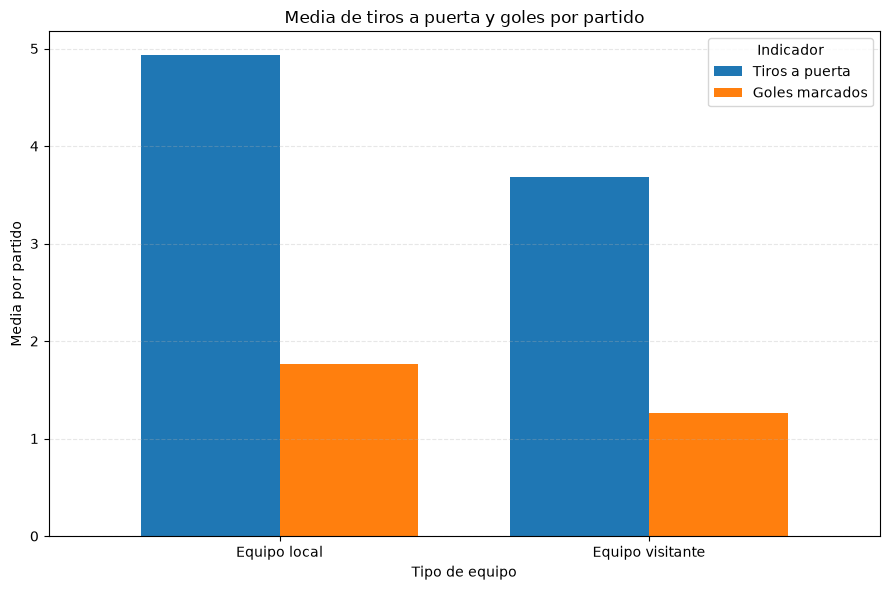

In [13]:
# Calcular la media por partido de cada equipo
estadisticas = pd.DataFrame({
    "Tiros a puerta": [
        partidos["home_sot"].mean(),
        partidos["away_sot"].mean()
    ],
    "Goles marcados": [
        partidos["home_score"].mean(),
        partidos["away_score"].mean()
    ]
}, index=["Equipo local", "Equipo visitante"])

# Crear gráfico de barras agrupadas
ax = estadisticas.plot(
    kind="bar",
    figsize=(9, 6),
    width=0.75
)

ax.set_title("Media de tiros a puerta y goles por partido")
ax.set_xlabel("Tipo de equipo")
ax.set_ylabel("Media por partido")
ax.set_xticklabels(
    estadisticas.index,
    rotation=0
)
ax.legend(title="Indicador")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# Copiar el dataset
xg = df.copy()

# Convertir las columnas necesarias a valores numéricos
columnas = [
    "home_score", "away_score",
    "home_total_shots", "away_total_shots",
    "home_sot", "away_sot"
]

for col in columnas:
    xg[col] = pd.to_numeric(xg[col], errors="coerce")

# Conservar partidos con todos los datos necesarios
xg = xg.dropna(subset=columnas).copy()

# Separar tiros a puerta y tiros fuera de puerta
xg["home_shots_off_target"] = (
    xg["home_total_shots"] - xg["home_sot"]
).clip(lower=0)

xg["away_shots_off_target"] = (
    xg["away_total_shots"] - xg["away_sot"]
).clip(lower=0)

# Estimación exploratoria:
# 0.20 xG por tiro a puerta
# 0.03 xG por tiro que no va a puerta
xg["home_xG_estimado"] = (
    xg["home_sot"] * 0.20
    + xg["home_shots_off_target"] * 0.03
)

xg["away_xG_estimado"] = (
    xg["away_sot"] * 0.20
    + xg["away_shots_off_target"] * 0.03
)

# Mostrar una selección de resultados
columnas_resultado = [
    "home_team", "away_team",
    "home_score", "away_score",
    "home_xG_estimado", "away_xG_estimado"
]

print(xg[columnas_resultado].head(10).round(2))

        home_team     away_team  home_score  away_score  home_xG_estimado  \
0          Mexico  South Africa         2.0         0.0              1.16   
1  Korea Republic       Czechia         2.0         1.0              1.47   
2          Canada   Bosnia–Herz         1.0         1.0              1.07   
3   United States      Paraguay         4.0         1.0              1.50   
4           Qatar   Switzerland         1.0         1.0              0.89   
5          Brazil       Morocco         1.0         1.0              1.21   
6       Australia       Türkiye         2.0         0.0              0.95   
7           Haiti      Scotland         0.0         1.0              0.79   
8         Germany       Curaçao         7.0         1.0              2.82   
9     Netherlands         Japan         2.0         2.0              1.32   

   away_xG_estimado  
0              0.43  
1              0.89  
2              0.75  
3              0.44  
4              1.97  
5              0.93 

In [ ]:

resumen = pd.DataFrame({
    "Goles reales": [
        xg["home_score"].mean(),
        xg["away_score"].mean()
    ],
    "xG estimado": [
        xg["home_xG_estimado"].mean(),
        xg["away_xG_estimado"].mean()
    ]
}, index=["Locales", "Visitantes"])

ax = resumen.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

ax.set_title("Goles reales frente a xG estimado")
ax.set_xlabel("Equipo")
ax.set_ylabel("Media por partido")
ax.set_xticklabels(resumen.index, rotation=0)
ax.legend(title="Indicador")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nMedia por partido:")
print(resumen.round(2))

Distribución de resultados
                    Partidos  Porcentaje (%)
resultado                                   
Victoria local            50            50.0
Empate                    20            20.0
Victoria visitante        30            30.0


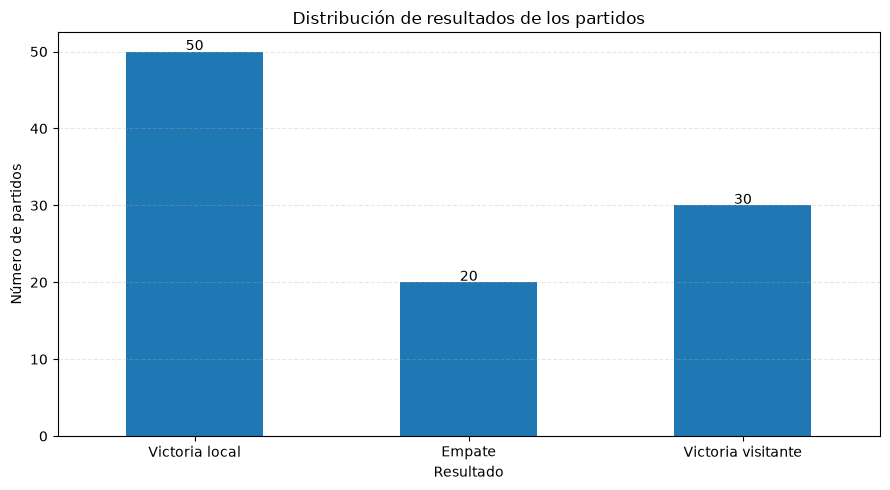

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Copia de trabajo
partidos = df.copy()

# Convertir marcadores a valores numéricos
partidos["home_score"] = pd.to_numeric(
    partidos["home_score"], errors="coerce"
)
partidos["away_score"] = pd.to_numeric(
    partidos["away_score"], errors="coerce"
)

# Eliminar partidos sin marcador completo
partidos = partidos.dropna(
    subset=["home_score", "away_score"]
).copy()

# Clasificar resultados
partidos["resultado"] = "Empate"

partidos.loc[
    partidos["home_score"] > partidos["away_score"],
    "resultado"
] = "Victoria local"

partidos.loc[
    partidos["home_score"] < partidos["away_score"],
    "resultado"
] = "Victoria visitante"

# Calcular frecuencias y porcentajes
orden = [
    "Victoria local",
    "Empate",
    "Victoria visitante"
]

frecuencias = partidos["resultado"].value_counts().reindex(
    orden, fill_value=0
)

porcentajes = frecuencias / len(partidos) * 100

print("Distribución de resultados")
print(pd.DataFrame({
    "Partidos": frecuencias,
    "Porcentaje (%)": porcentajes.round(2)
}))

# Gráfico de barras
ax = frecuencias.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribución de resultados de los partidos"
)

ax.set_xlabel("Resultado")
ax.set_ylabel("Número de partidos")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)

for i, valor in enumerate(frecuencias):
    ax.text(i, valor + 0.2, str(valor), ha="center")

plt.tight_layout()
plt.show()


Distribución de resultados
                    Partidos  Porcentaje (%)
resultado                                   
Victoria local            50            50.0
Empate                    20            20.0
Victoria visitante        30            30.0


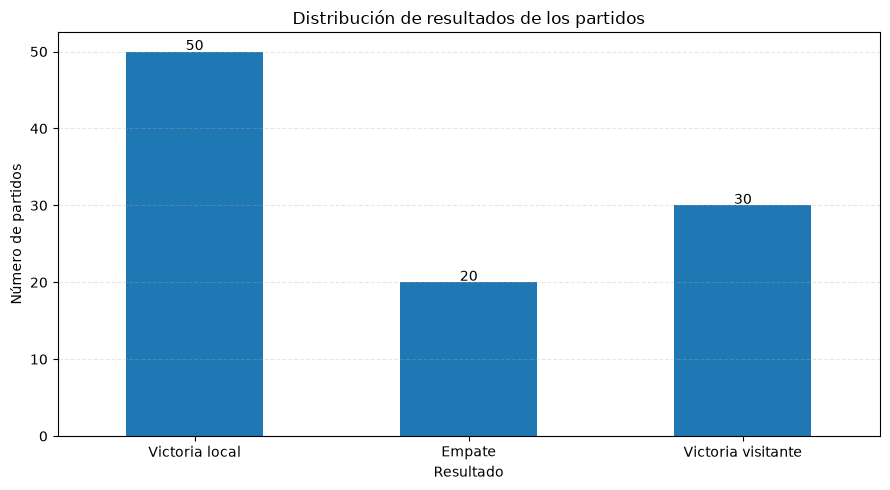

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Copia de trabajo
partidos = df.copy()

# Convertir marcadores a valores numéricos
partidos["home_score"] = pd.to_numeric(
    partidos["home_score"], errors="coerce"
)
partidos["away_score"] = pd.to_numeric(
    partidos["away_score"], errors="coerce"
)

# Eliminar partidos sin marcador completo
partidos = partidos.dropna(
    subset=["home_score", "away_score"]
).copy()

# Clasificar resultados
partidos["resultado"] = "Empate"

partidos.loc[
    partidos["home_score"] > partidos["away_score"],
    "resultado"
] = "Victoria local"

partidos.loc[
    partidos["home_score"] < partidos["away_score"],
    "resultado"
] = "Victoria visitante"

# Calcular frecuencias y porcentajes
orden = [
    "Victoria local",
    "Empate",
    "Victoria visitante"
]

frecuencias = partidos["resultado"].value_counts().reindex(
    orden, fill_value=0
)

porcentajes = frecuencias / len(partidos) * 100

print("Distribución de resultados")
print(pd.DataFrame({
    "Partidos": frecuencias,
    "Porcentaje (%)": porcentajes.round(2)
}))

# Gráfico de barras
ax = frecuencias.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribución de resultados de los partidos"
)

ax.set_xlabel("Resultado")
ax.set_ylabel("Número de partidos")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)

for i, valor in enumerate(frecuencias):
    ax.text(i, valor + 0.2, str(valor), ha="center")

plt.tight_layout()
plt.show()


ESTADÍSTICAS DE ASISTENCIA POR FASE


,partidos,asistencia_media,asistencia_mediana,asistencia_maxima,asistencia_minima
round,,,,,
Third-place match,1,64478.0,64478.0,64478,64478
Group stage,72,64508.0,68239.0,80824,42942
Round of 32,16,66134.0,68802.0,80824,43036
Quarter-finals,4,66956.0,66762.0,70492,63811
Semi-finals,2,69208.0,69208.0,70176,68239
Round of 16,8,69612.0,68550.0,80824,52497
Final,1,80663.0,80663.0,80663,80663


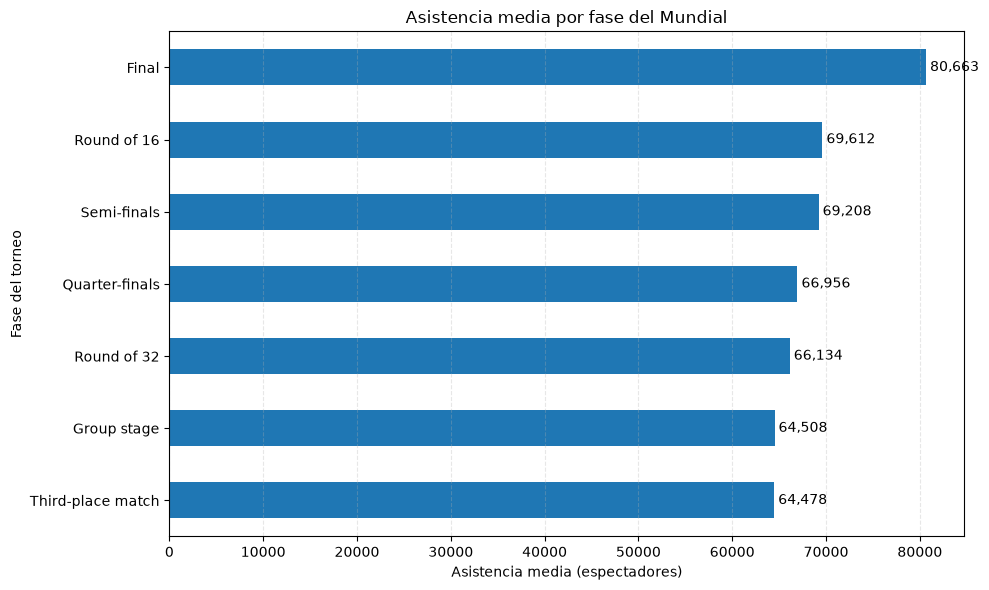

In [18]:

import pandas as pd
import matplotlib.pyplot as plt

#Aumenta la asistencia segun la fase del mundial ?

# Crear una copia de trabajo
datos = df.copy()

# Convertir asistencia a formato numérico
datos["attendance"] = pd.to_numeric(
    datos["attendance"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Eliminar filas sin fase o asistencia
datos = datos.dropna(subset=["round", "attendance"])

# Calcular estadísticas por fase
resumen_fases = datos.groupby("round").agg(
    partidos=("attendance", "count"),
    asistencia_media=("attendance", "mean"),
    asistencia_mediana=("attendance", "median"),
    asistencia_maxima=("attendance", "max"),
    asistencia_minima=("attendance", "min")
)

# Ordenar de menor a mayor asistencia media
resumen_fases = resumen_fases.sort_values(
    "asistencia_media",
    ascending=True
)

# Mostrar tabla de resultados
print("ESTADÍSTICAS DE ASISTENCIA POR FASE")
display(resumen_fases.round(0))

# Gráfico de barras horizontales
ax = resumen_fases["asistencia_media"].plot(
    kind="barh",
    figsize=(10, 6),
    title="Asistencia media por fase del Mundial"
)

ax.set_xlabel("Asistencia media (espectadores)")
ax.set_ylabel("Fase del torneo")
ax.grid(axis="x", linestyle="--", alpha=0.3)

# Añadir valores al final de las barras
for i, valor in enumerate(resumen_fases["asistencia_media"]):
    ax.text(valor, i, f" {valor:,.0f}", va="center")

plt.tight_layout()
plt.show()


NameError: name 'Patch' is not defined

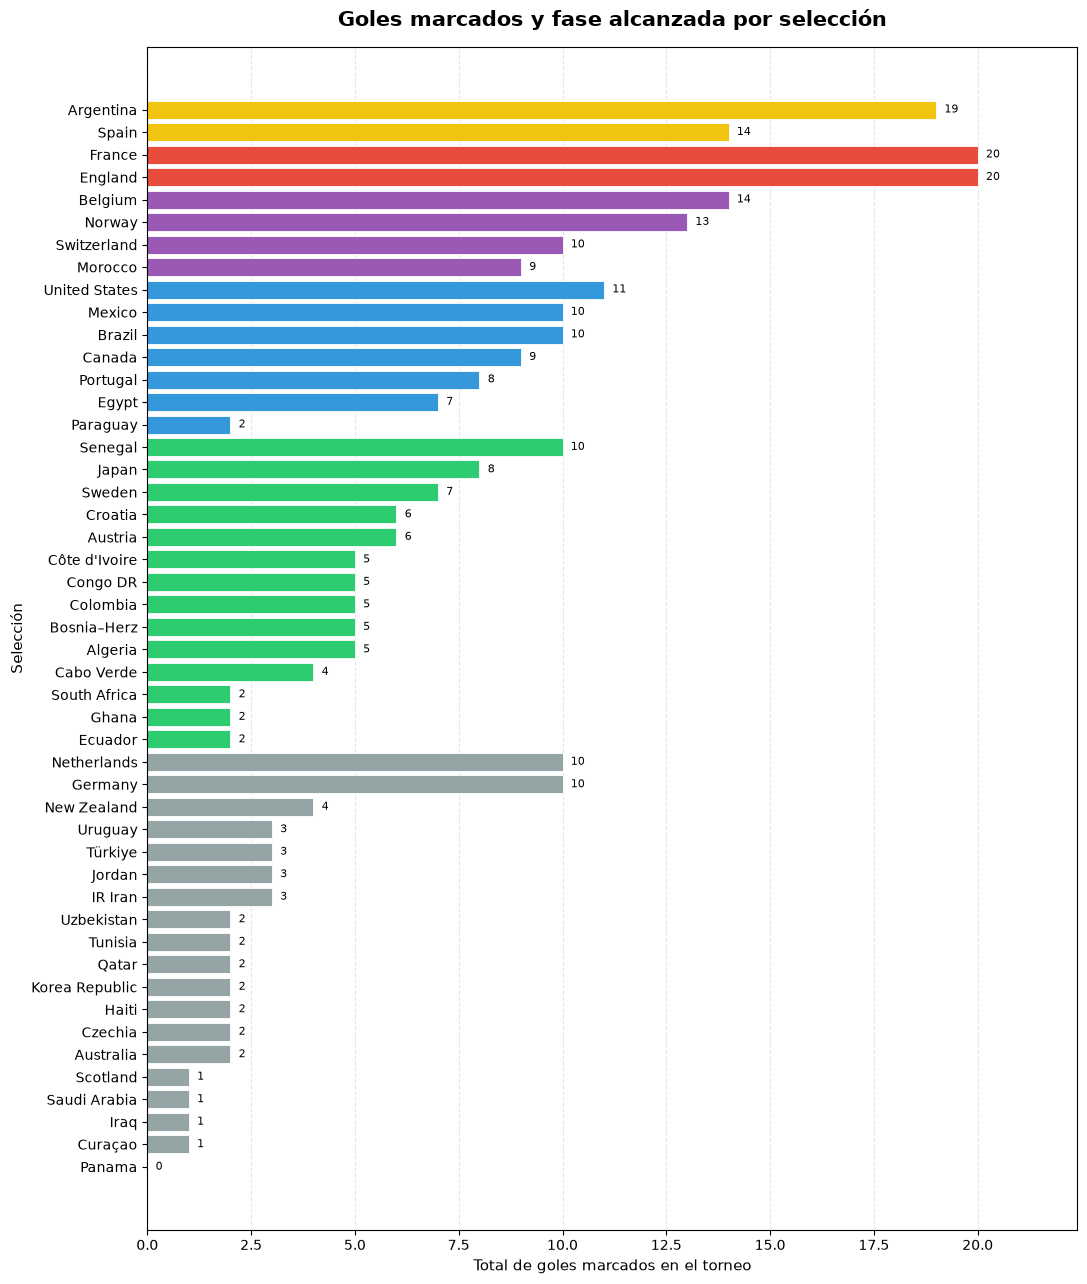

In [20]:


# 2. Definir el orden de las fases
orden_fases = {
    "Group stage": 1,
    "Round of 32": 2,
    "Round of 16": 3,
    "Quarter-finals": 4,
    "Semi-finals": 5,
    "Third-place match": 5,
    "Final": 6
}

# 3. Nombres de las fases para mostrar en el gráfico
nombres_fases = {
    1: "Fase de grupos",
    2: "Dieciseisavos",
    3: "Octavos de final",
    4: "Cuartos de final",
    5: "Semifinales / tercer puesto",
    6: "Final"
}

# 4. Colores muy diferenciados
colores_fase = {
    1: "#95A5A6",  # Gris
    2: "#2ECC71",  # Verde
    3: "#3498DB",  # Azul
    4: "#9B59B6",  # Morado
    5: "#E74C3C",  # Rojo
    6: "#F1C40F"   # Dorado
}

# 5. Asignar el nivel de fase a cada partido
df["nivel_fase"] = df["round"].map(orden_fases)

# Comprobar si hay fases sin clasificar
fases_sin_clasificar = df.loc[
    df["nivel_fase"].isna(), "round"
].unique()

if len(fases_sin_clasificar) > 0:
    print("Fases sin clasificar:", fases_sin_clasificar)

# 6. Conservar partidos con marcador completo
partidos = df.dropna(
    subset=["home_score", "away_score"]
).copy()

# Convertir los marcadores a números
partidos["home_score"] = pd.to_numeric(
    partidos["home_score"], errors="coerce"
)
partidos["away_score"] = pd.to_numeric(
    partidos["away_score"], errors="coerce"
)

partidos = partidos.dropna(
    subset=["home_score", "away_score"]
)

# 7. Crear una tabla para los equipos locales
locales = partidos[
    ["home_team", "home_score", "nivel_fase"]
].rename(columns={
    "home_team": "equipo",
    "home_score": "goles"
})

# 8. Crear una tabla para los equipos visitantes
visitantes = partidos[
    ["away_team", "away_score", "nivel_fase"]
].rename(columns={
    "away_team": "equipo",
    "away_score": "goles"
})

# 9. Unir ambas tablas
datos_equipos = pd.concat(
    [locales, visitantes],
    ignore_index=True
)

# 10. Calcular goles totales y fase más avanzada
resumen = datos_equipos.groupby("equipo").agg(
    goles_marcados=("goles", "sum"),
    fase_alcanzada=("nivel_fase", "max")
).reset_index()

# Eliminar equipos cuya fase no se haya podido identificar
resumen = resumen.dropna(
    subset=["fase_alcanzada"]
)

resumen["fase_alcanzada"] = (
    resumen["fase_alcanzada"].astype(int)
)

# 11. Ordenar por fase y después por goles
resumen = resumen.sort_values(
    ["fase_alcanzada", "goles_marcados", "equipo"],
    ascending=[True, True, True]
).reset_index(drop=True)

# 12. Asignar un color a cada equipo según su fase
colores = [
    colores_fase[fase]
    for fase in resumen["fase_alcanzada"]
]

# 13. Crear el gráfico
fig, ax = plt.subplots(
    figsize=(12, max(10, len(resumen) * 0.32))
)

barras = ax.barh(
    resumen["equipo"],
    resumen["goles_marcados"],
    color=colores,
    edgecolor="white",
    linewidth=0.6
)

# 14. Mostrar el número de goles al final de cada barra
for barra, goles in zip(
    barras, resumen["goles_marcados"]
):
    ax.text(
        barra.get_width() + 0.2,
        barra.get_y() + barra.get_height() / 2,
        f"{goles:.0f}",
        va="center",
        fontsize=8
    )

# 15. Título y etiquetas
ax.set_title(
    "Goles marcados y fase alcanzada por selección",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Total de goles marcados en el torneo",
    fontsize=11
)

ax.set_ylabel(
    "Selección",
    fontsize=11
)

# 16. Mejorar la lectura
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Dejar espacio para las etiquetas de goles
max_goles = resumen["goles_marcados"].max()
ax.set_xlim(0, max_goles * 1.12)

# 17. Crear la leyenda de colores
leyenda = [
    Patch(
        facecolor=colores_fase[nivel],
        label=nombre
    )
    for nivel, nombre in nombres_fases.items()
]

ax.legend(
    handles=leyenda,
    title="Fase más avanzada",
    loc="lower right",
    frameon=True
)

# 18. Mostrar el gráfico
plt.tight_layout()
plt.show()

# 19. Mostrar la tabla con los resultados
resumen["fase_nombre"] = resumen[
    "fase_alcanzada"
].map(nombres_fases)

display(
    resumen.sort_values(
        ["fase_alcanzada", "goles_marcados"],
        ascending=[False, False]
    )[
        ["equipo", "goles_marcados", "fase_nombre"]
    ]
)
